In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', str(ROOT / 'raw')))

B: 18 dome flats combined


V: 15 dome flats combined


R: 20 dome flats combined


Aligned: NGC7129_-0001FLTRB.fit


Aligned: NGC7129_-0002FLTRB.fit


...

Aligned: NGC7129_-0012FLTRR.fit


Aligned: NGC7129_-0013FLTRR.fit


Aligned: NGC7129_-0014FLTRR.fit


Aligned: NGC7129_-0015FLTRR.fit


R: 15 exposures combined


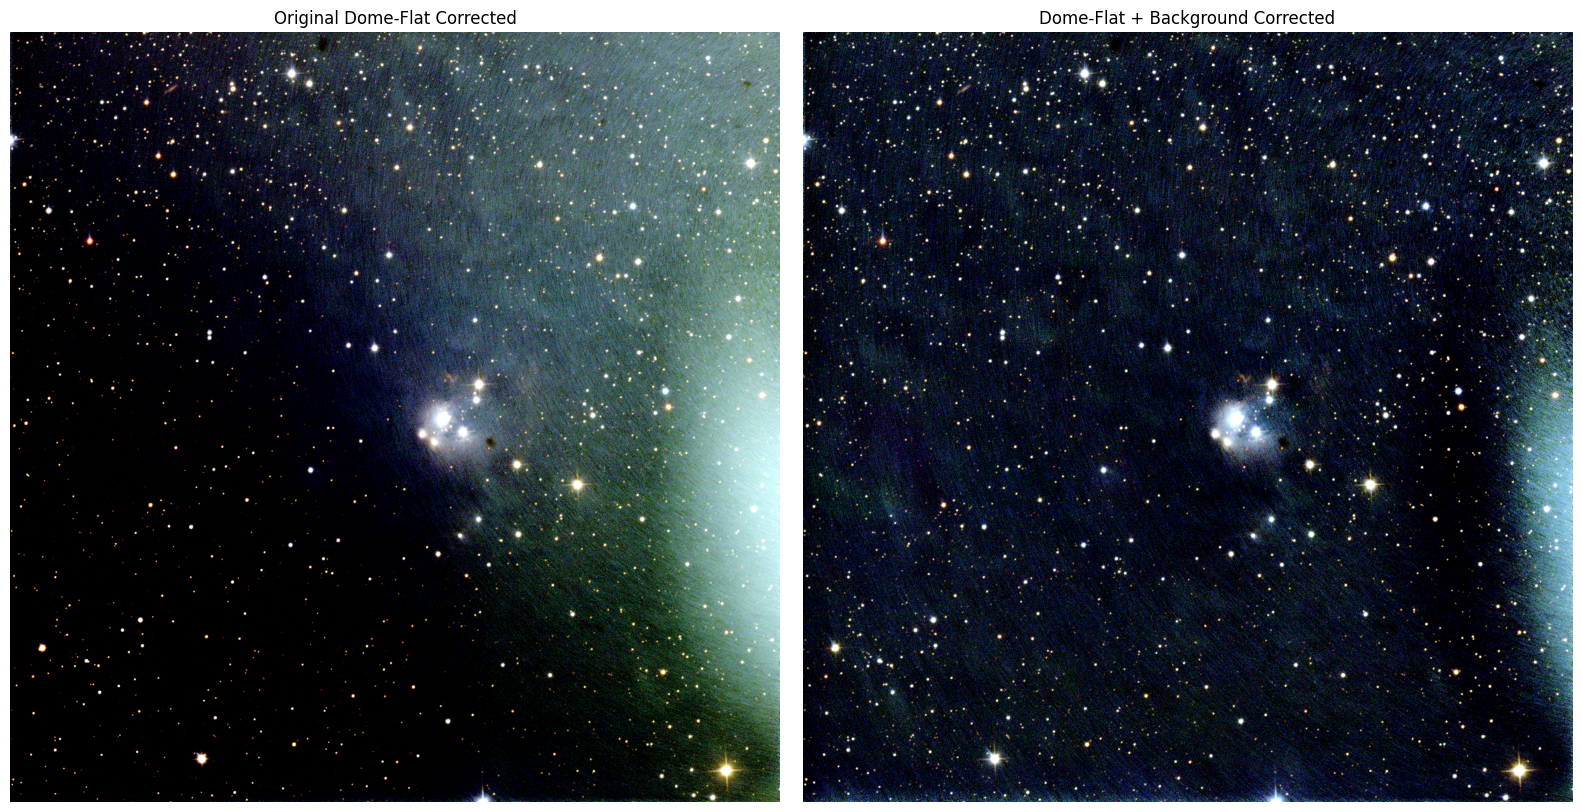


Processing complete!
Saved files to: /Users/gracedavis/Documents/Codex/2026-10-19/oth/work/clean_submission/results
Original: NGC7129_dome_corrected.png
Corrected: NGC7129_background_corrected.png


In [2]:

from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
import astroalign as aa
from scipy.ndimage import median_filter, gaussian_filter


# File paths
base = RAW
flat_dir = RAW / 'Dome Flats'
science_dir = base / 'Exercise D1'
out = OUT

out.mkdir(exist_ok=True, parents=True)

# Excluded flat frames
excluded = {
    'B': {9, 19},
    'V': {4, 6, 8, 16, 20},
    'R': set()
}

# Display settings
BACKGROUND_SIGMA = 120
BACKGROUND_MEDIAN_SIZE = 31
DISPLAY_PERCENTILE = 99.5
STRETCH = 10.0

manifest = {
    'excluded_flats': {
        k: sorted(v) for k, v in excluded.items()
    },
    'science': {},
    'failed_alignment': {}
}

# Read dark-corrected fits files

def zero_based(path):
    data, header = fits.getdata(path, header=True)

    calstat = header.get('CALSTAT', '')

    if 'D' not in calstat:
        raise ValueError(
            f'{path.name}: expected dark-corrected input'
        )

    if 'F' in calstat:
        raise ValueError(
            f'{path.name}: already flat-field corrected'
        )

    # Restore zero-based pixel values from FITS pedestal
    pedestal = header.get('PEDESTAL', 0)

    return data.astype(np.float32) + pedestal


# Create master dome flats

master_flats = {}

for band in 'BVR':

    flat_files = [
        flat_dir / f'Dome Flat-{i:04d}_{band}.fit'
        for i in range(1, 21)
        if i not in excluded[band]
    ]

    normalized_flats = []

    for path in flat_files:

        if not path.exists():
            raise FileNotFoundError(path)

        data, header = fits.getdata(path, header=True)

        if not header['FILTER'].strip().endswith(band):
            raise ValueError(
                f'Wrong filter in {path.name}'
            )

        flat = zero_based(path)

        level = np.nanmedian(flat)

        if not np.isfinite(level) or level <= 0:
            raise ValueError(
                f'Invalid flat level: {path.name}'
            )

        normalized_flats.append(flat / level)

    master = np.nanmedian(
        np.stack(normalized_flats),
        axis=0
    )

    master /= np.nanmedian(master)

    master[
        ~np.isfinite(master) | (master <= 0)
    ] = np.nan

    master_flats[band] = master

    fits.writeto(
        out / f'master_{band}_domeflat.fit',
        master,
        overwrite=True
    )

    print(
        f'{band}: {len(flat_files)} dome flats combined'
    )


# Apply flat-field correction

def calibrate(path, band):

    data = zero_based(path)

    if data.shape != master_flats[band].shape:
        raise ValueError(
            f'Image shape mismatch: {path.name}'
        )

    return data / master_flats[band]


# Align and median-combine science images

science_files = {
    band: sorted(
        science_dir.glob(f'NGC7129_*FLTR{band}.fit')
    )
    for band in 'BVR'
}

for band in 'BVR':
    if not science_files[band]:
        raise FileNotFoundError(
            f'No NGC 7129 {band}-band files found'
        )

reference_path = science_files['V'][0]
reference = calibrate(reference_path, 'V')

masters = {}

for band, files in science_files.items():

    aligned = []
    used = []
    failed = []

    for path in files:

        data = calibrate(path, band)

        try:

            if path == reference_path:
                registered = data

            else:
                registered, footprint = aa.register(
                    np.ma.masked_invalid(data),
                    np.ma.masked_invalid(reference),
                    propagate_mask=True
                )

                registered[footprint] = np.nan

            aligned.append(registered)
            used.append(path.name)

            print('Aligned:', path.name)

        except (aa.MaxIterError, ValueError) as exc:

            failed.append({
                'file': path.name,
                'reason': str(exc)
            })

            print('Alignment failed:', path.name)

    if not aligned:
        raise RuntimeError(
            f'No usable {band}-band images'
        )

    with warnings.catch_warnings():
        warnings.simplefilter(
            'ignore',
            RuntimeWarning
        )

        masters[band] = np.nanmedian(
            np.stack(aligned),
            axis=0
        )

    fits.writeto(
        out / f'NGC7129_{band}_dome_corrected.fit',
        masters[band],
        overwrite=True
    )

    manifest['science'][band] = used
    manifest['failed_alignment'][band] = failed

    print(
        f'{band}: {len(used)} exposures combined'
    )


# Estimate and subtract large-scale background

def subtract_background(image):

    data = np.asarray(image, dtype=float)

    valid = np.isfinite(data)

    if not np.any(valid):
        raise ValueError('No valid image pixels')

    fill_value = np.nanmedian(data)

    filled = np.where(
        valid,
        data,
        fill_value
    )

    # Median filtering reduces bright-star influence
    filtered = median_filter(
        filled,
        size=BACKGROUND_MEDIAN_SIZE
    )

    # Estimate smoothly varying background
    background = gaussian_filter(
        filtered,
        sigma=BACKGROUND_SIGMA
    )

    corrected = data - background

    corrected[~valid] = np.nan

    return corrected, background


corrected_masters = {}
background_models = {}

for band in 'BVR':

    corrected, background = subtract_background(
        masters[band]
    )

    corrected_masters[band] = corrected
    background_models[band] = background

    fits.writeto(
        out / f'NGC7129_{band}_background_corrected.fit',
        corrected,
        overwrite=True
    )


# Normalize and stretch for rgb display

def display_channel(image):

    data = np.asarray(image, dtype=float)

    finite = np.isfinite(data)

    signal = np.maximum(
        data - np.nanmedian(data[finite]),
        0
    )

    scale = np.nanpercentile(
        signal[finite],
        DISPLAY_PERCENTILE
    )

    if not np.isfinite(scale) or scale <= 0:
        return np.zeros_like(data)

    signal = np.clip(
        signal / scale,
        0,
        1
    )

    stretched = (
        np.arcsinh(STRETCH * signal)
        / np.arcsinh(STRETCH)
    )

    return np.clip(
        np.nan_to_num(stretched),
        0,
        1
    )


# RGB order: Red, Green, Blue = R, V, B
rgb_original = np.dstack([
    display_channel(masters[band])
    for band in 'RVB'
])

rgb_corrected = np.dstack([
    display_channel(corrected_masters[band])
    for band in 'RVB'
])


# Save both composites

plt.imsave(
    out / 'NGC7129_dome_corrected.png',
    rgb_original,
    origin='lower'
)

plt.imsave(
    out / 'NGC7129_background_corrected.png',
    rgb_corrected,
    origin='lower'
)

manifest_path = out / 'NGC7129_processing_manifest.json'

manifest_path.write_text(
    json.dumps(manifest, indent=2)
)


fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8)
)

axes[0].imshow(
    rgb_original,
    origin='lower'
)

axes[0].set_title(
    'Original Dome-Flat Corrected'
)

axes[0].axis('off')

axes[1].imshow(
    rgb_corrected,
    origin='lower'
)

axes[1].set_title(
    'Dome-Flat + Background Corrected'
)

axes[1].axis('off')

plt.tight_layout()
plt.show()

print('\nProcessing complete!')
print('Saved files to:', out)
print('Original: NGC7129_dome_corrected.png')
print('Corrected: NGC7129_background_corrected.png')